# K-means clustering

In dit notebook gaan we k-means clustering toepassen op de Aria dataset.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [2]:
df = pd.read_csv("aria_users.csv")
df.head()

,user_id,age,country,region,education_level,device_type,subscription_type,signup_date,primary_use_case,daily_usage_minutes,sessions_per_week,monthly_spend_eur,trust_in_ai,satisfaction_score,nps_score,churned
0,1001,37.0,Sweden,Northern Europe,Master,Mobile,Free,2024-08-18,Personal Assistant,2.5,0,0.26,NaN,4.0,6,No
1,1002,23.0,Netherlands,Western Europe,Bachelor,Tablet,Free,2025-08-29,Coding,21.2,3,0.06,9.0,2.0,39,No
2,1003,42.0,France,Western Europe,PhD,Tablet,Free,2025-08-16,Writing,9.0,3,0.17,8.9,2.0,46,No
3,1004,44.0,Spain,Southern Europe,Bachelor,Mobile,Premium,2025-05-02,Coding,23.8,2,9.90,6.1,NaN,45,No
4,1005,16.0,Netherlands,Western Europe,Bachelor,Desktop,Free,2025-09-06,Coding,16.0,1,0.03,5.9,NaN,-4,No


In [3]:
features = ["subscription_type", "primary_use_case", "daily_usage_minutes", "nps_score", "age"]
df = df[features]
df.head()

,subscription_type,primary_use_case,daily_usage_minutes,nps_score,age
0,Free,Personal Assistant,2.5,6,37.0
1,Free,Coding,21.2,39,23.0
2,Free,Writing,9.0,46,42.0
3,Premium,Coding,23.8,45,44.0
4,Free,Coding,16.0,-4,16.0


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 623 entries, 0 to 622
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   subscription_type    623 non-null    str    
 1   primary_use_case     623 non-null    str    
 2   daily_usage_minutes  623 non-null    float64
 3   nps_score            623 non-null    int64  
 4   age                  599 non-null    float64
dtypes: float64(2), int64(1), str(2)
memory usage: 24.5 KB


In [5]:
df["subscription_type"].unique()

<StringArray>
['Free', 'Premium', 'Premium Plus']
Length: 3, dtype: str

In [6]:
mapping = {
    "Free": 0,
    "Premium": 5,
    "Premium Plus": 15
}

df["subscription_type"] = df["subscription_type"].map(mapping)
df.head()

,subscription_type,primary_use_case,daily_usage_minutes,nps_score,age
0,0,Personal Assistant,2.5,6,37.0
1,0,Coding,21.2,39,23.0
2,0,Writing,9.0,46,42.0
3,5,Coding,23.8,45,44.0
4,0,Coding,16.0,-4,16.0


In [7]:
df2 = pd.get_dummies(df["primary_use_case"])
df2.head()

,Coding,Customer Support,Personal Assistant,Research,Translation,Writing
0,False,False,True,False,False,False
1,True,False,False,False,False,False
2,False,False,False,False,False,True
3,True,False,False,False,False,False
4,True,False,False,False,False,False


In [8]:
df = pd.concat([df, df2], axis=1)
df.head()

,subscription_type,primary_use_case,daily_usage_minutes,nps_score,age,Coding,Customer Support,Personal Assistant,Research,Translation,Writing
0,0,Personal Assistant,2.5,6,37.0,False,False,True,False,False,False
1,0,Coding,21.2,39,23.0,True,False,False,False,False,False
2,0,Writing,9.0,46,42.0,False,False,False,False,False,True
3,5,Coding,23.8,45,44.0,True,False,False,False,False,False
4,0,Coding,16.0,-4,16.0,True,False,False,False,False,False


In [9]:
df = df.drop("primary_use_case", axis=1)

df.head()

,subscription_type,daily_usage_minutes,nps_score,age,Coding,Customer Support,Personal Assistant,Research,Translation,Writing
0,0,2.5,6,37.0,False,False,True,False,False,False
1,0,21.2,39,23.0,True,False,False,False,False,False
2,0,9.0,46,42.0,False,False,False,False,False,True
3,5,23.8,45,44.0,True,False,False,False,False,False
4,0,16.0,-4,16.0,True,False,False,False,False,False


In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 623 entries, 0 to 622
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   subscription_type    623 non-null    int64  
 1   daily_usage_minutes  623 non-null    float64
 2   nps_score            623 non-null    int64  
 3   age                  599 non-null    float64
 4   Coding               623 non-null    bool   
 5   Customer Support     623 non-null    bool   
 6   Personal Assistant   623 non-null    bool   
 7   Research             623 non-null    bool   
 8   Translation          623 non-null    bool   
 9   Writing              623 non-null    bool   
dtypes: bool(6), float64(2), int64(2)
memory usage: 23.2 KB


we missen nog leeftijden, maar met opdrachtgever gecheckt, die mogen weg

In [11]:
df = df.dropna()
df.head()

,subscription_type,daily_usage_minutes,nps_score,age,Coding,Customer Support,Personal Assistant,Research,Translation,Writing
0,0,2.5,6,37.0,False,False,True,False,False,False
1,0,21.2,39,23.0,True,False,False,False,False,False
2,0,9.0,46,42.0,False,False,False,False,False,True
3,5,23.8,45,44.0,True,False,False,False,False,False
4,0,16.0,-4,16.0,True,False,False,False,False,False


## k-means

In [12]:
scaler = StandardScaler()
normalised_data = scaler.fit_transform(df)

df = pd.DataFrame(
    normalised_data,
    columns=df.columns
)

df.head()

,subscription_type,daily_usage_minutes,nps_score,age,Coding,Customer Support,Personal Assistant,Research,Translation,Writing
0,-0.679979,-1.011723,-0.670916,0.296377,-0.547128,-0.381203,2.247333,-0.450346,-0.327428,-0.518717
1,-0.679979,-0.174960,0.305308,-1.063259,1.827725,-0.381203,-0.444972,-0.450346,-0.327428,-0.518717
2,-0.679979,-0.720869,0.512385,0.781961,-0.547128,-0.381203,-0.444972,-0.450346,-0.327428,1.927832
3,0.348575,-0.058619,0.482803,0.976194,1.827725,-0.381203,-0.444972,-0.450346,-0.327428,-0.518717
4,-0.679979,-0.407643,-0.966742,-1.743077,1.827725,-0.381203,-0.444972,-0.450346,-0.327428,-0.518717


In [13]:
model = KMeans(n_clusters=2, random_state=42)
result = model.fit_transform(df)

labels = model.labels_
centroids = model.cluster_centers_

.\
.\
.\
.\
.\
.\
.\
.\
.\
.\
.\
.\
.\
.\
.

# Grafiekjes

Deze code is gegenereerd door claude, en aan jullie is straks de opdracht deze uit te gaan leggen. Maar eerst gaan we k-means maken.

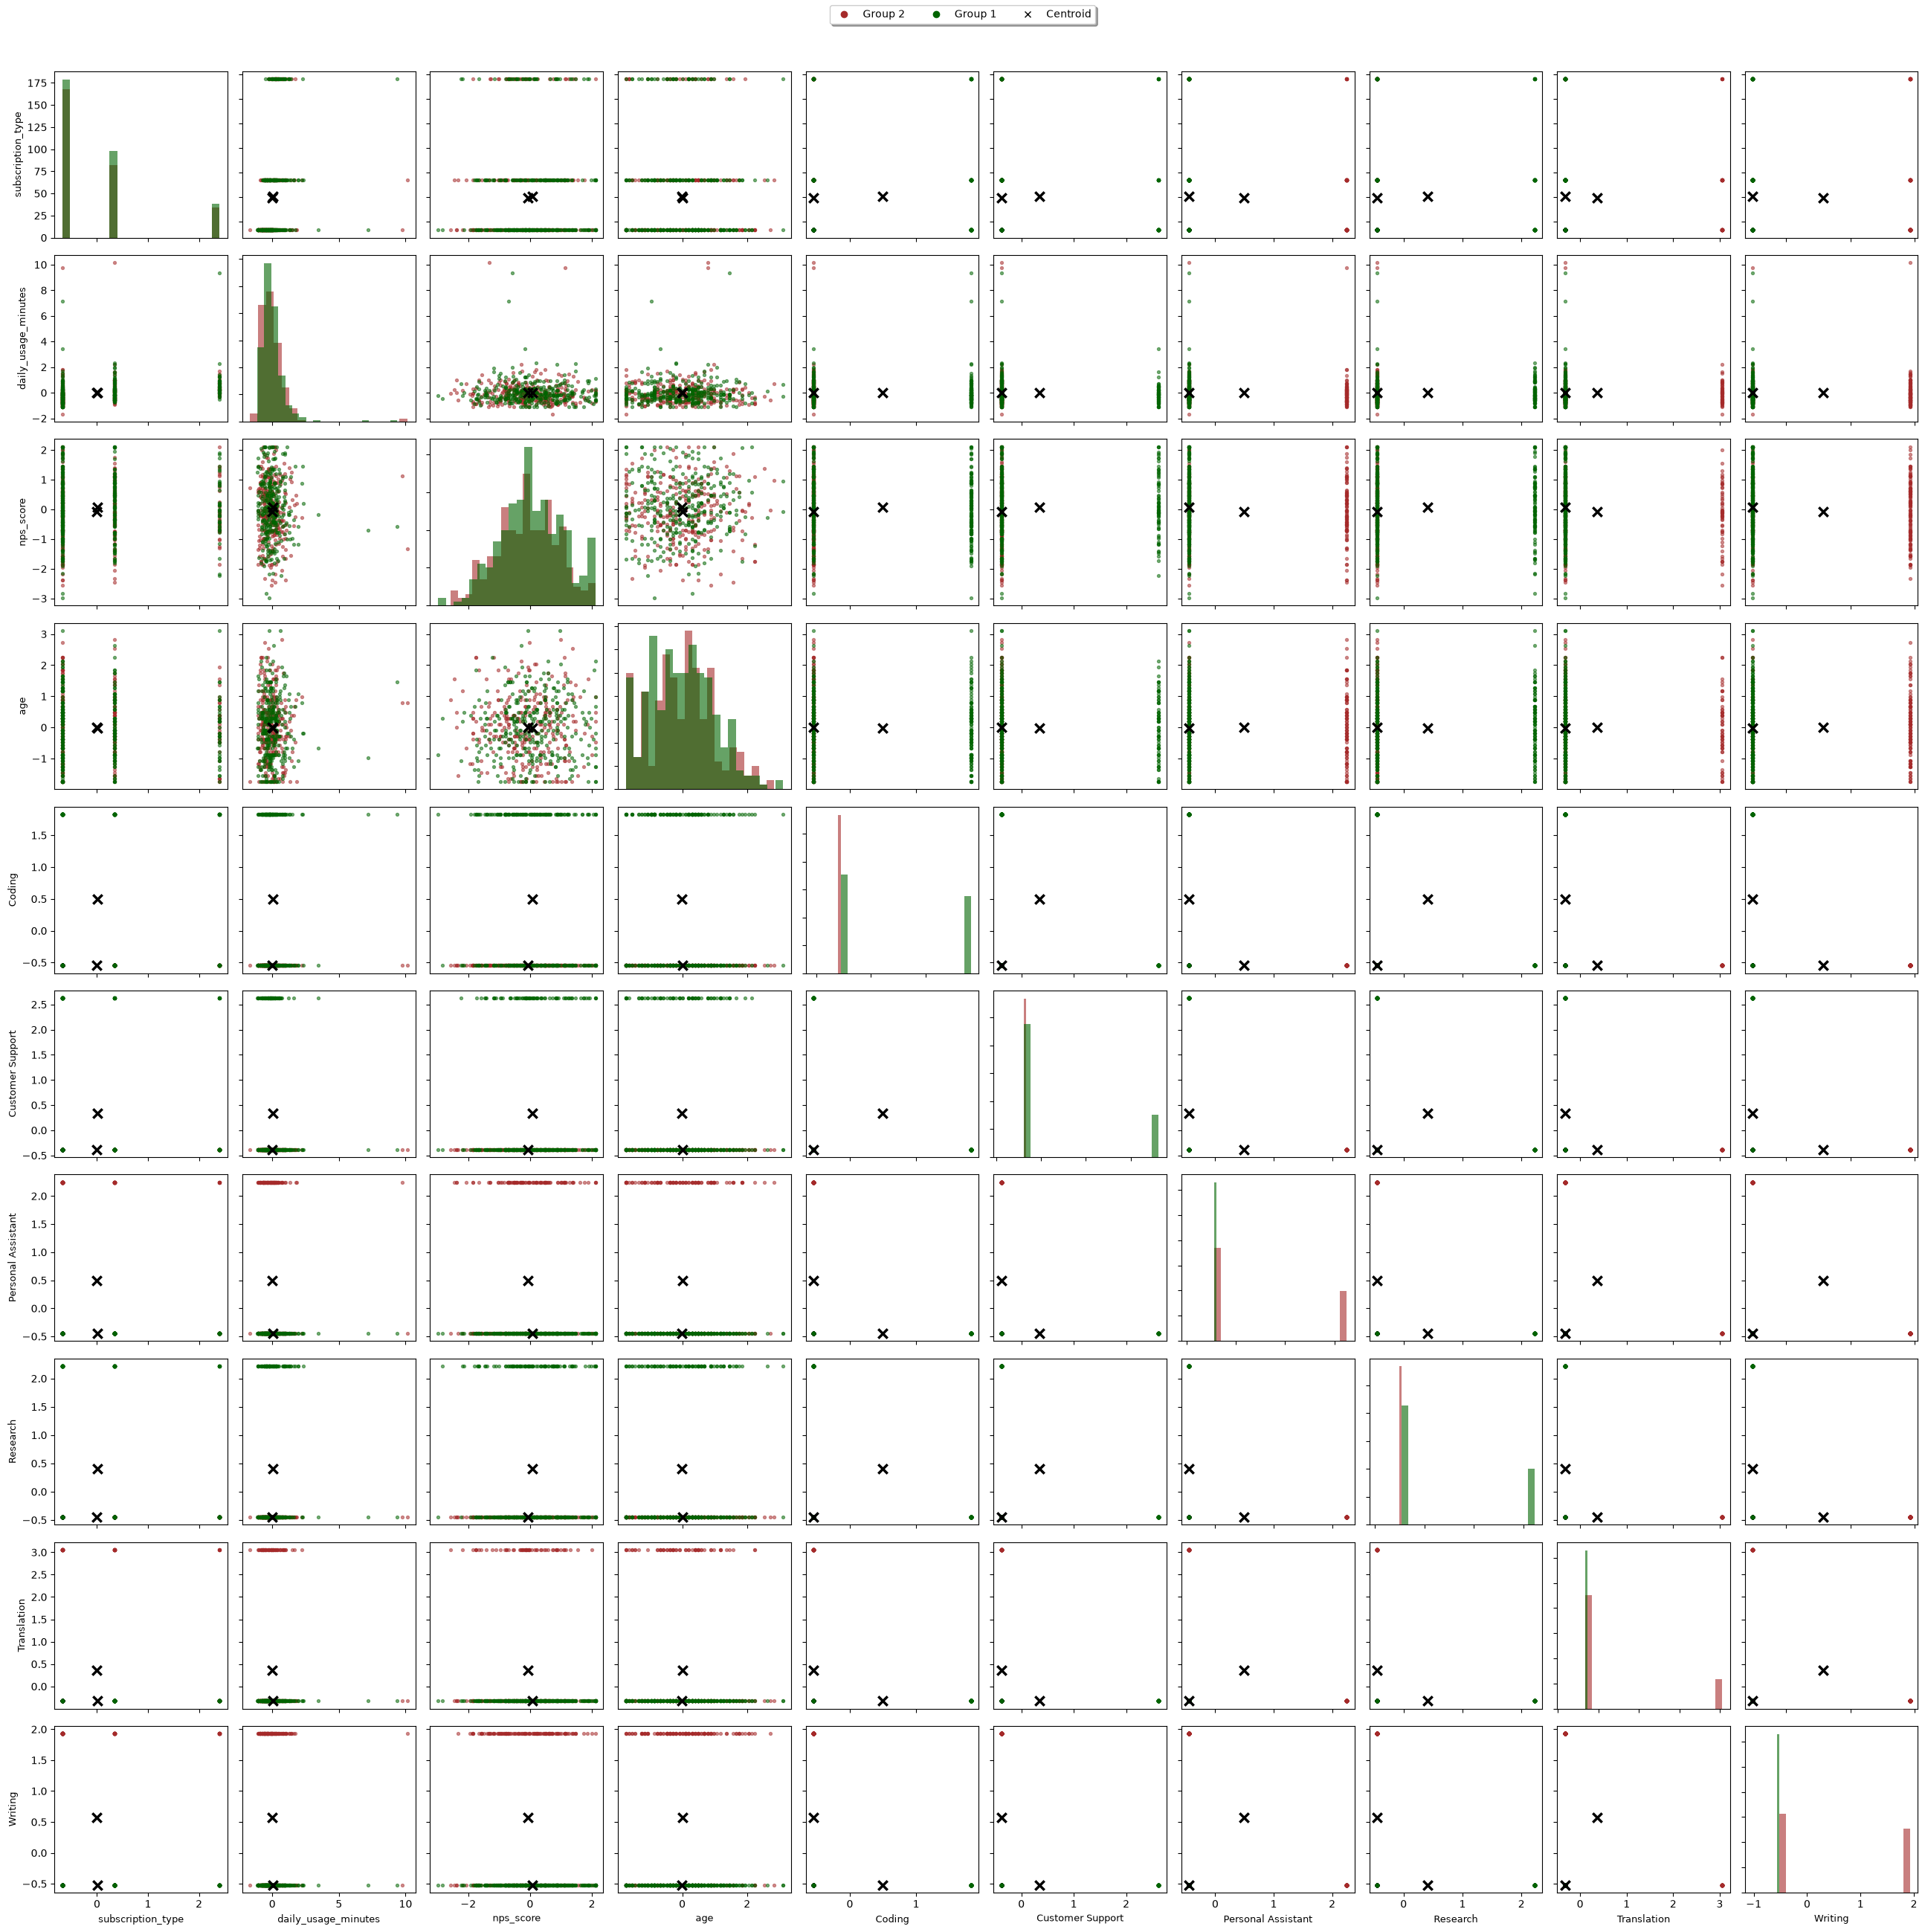

In [15]:
features = list(df.columns)

colors = {0: "Brown", 1: "DarkGreen"}
names = {0: "Group 2", 1: "Group 1"}

n = len(features)
fig, axes = plt.subplots(n, n, figsize=(2.6 * n, 2.6 * n))

for i, y_col in enumerate(features):          # rows    -> y-axis
    for j, x_col in enumerate(features):      # columns -> x-axis
        ax = axes[i, j]

        if i == j:
            # Diagonal: histogram per cluster shows how well a single column separates the groups
            for c in np.unique(labels):
                ax.hist(
                    df.loc[labels == c, x_col], 
                    bins=20, 
                    alpha=0.6, 
                    color=colors[c]
                )
        else:
            for c in np.unique(labels):
                mask = labels == c
                ax.scatter(
                    df.loc[mask, x_col], 
                    df.loc[mask, y_col],
                    s=8, 
                    alpha=0.5, 
                    color=colors[c]
                )
            ax.scatter(
                centroids[:, j], 
                centroids[:, i],
                marker="x", 
                s=80, 
                linewidths=2.5, 
                color="black", 
                zorder=10
            )

        # Only label the outer edges to keep it readable
        if i == n - 1:
            ax.set_xlabel(x_col, fontsize=9)
        else:
            ax.set_xticklabels([])
        if j == 0:
            ax.set_ylabel(y_col, fontsize=9)
        else:
            ax.set_yticklabels([])

# One shared legend
handles = [plt.Line2D([], [], marker="o", linestyle="", color=colors[c], label=names[c]) for c in sorted(colors)]
handles.append(plt.Line2D([], [], marker="x", linestyle="", color="black", label="Centroid"))
fig.legend(handles=handles, loc="upper center", ncol=3, fancybox=True, shadow=True)

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()